# Milestone 1: Image Preprocessing, Enhancement, & Data Splitting
**System**: Skin Cancer Detection and Classification System Using CNN-SVM  
**Objective**: Demonstrate OpenCV CLAHE contrast enhancement, resizing to 128x128, data augmentation, and leak-free splitting.

In [1]:
import os, sys
project_root = os.path.abspath('..') if os.path.exists('../dataset') else os.path.abspath('.')
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from src.preprocessing import (
    apply_clahe,
    preprocess_single_image,
    augment_image_array,
    create_leak_free_splits,
    index_image_paths,
    CLASS_NAMES
)
print('Preprocessing module imported.')

Preprocessing module imported.


## 1. Contrast-Limited Adaptive Histogram Equalization (CLAHE)
Enhances local lesion borders in LAB color space without color distortion.

2026-10-28 17:31:40,090 - INFO - Indexed 10015 images across search directories.


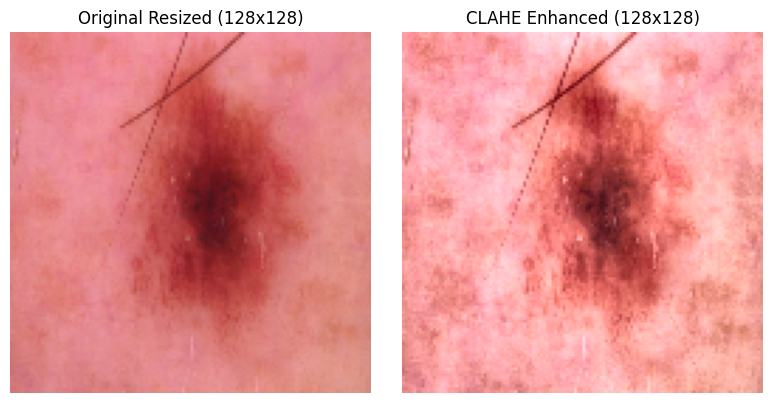

In [2]:
image_map = index_image_paths()
sample_id = list(image_map.keys())[0]
sample_path = image_map[sample_id]

raw_bgr = cv2.imread(sample_path)
raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
resized = cv2.resize(raw_rgb, (128, 128))
enhanced = apply_clahe(resized)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(resized)
axes[0].set_title('Original Resized (128x128)')
axes[0].axis('off')

axes[1].imshow(enhanced)
axes[1].set_title('CLAHE Enhanced (128x128)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## 2. Real-Time Data Augmentation

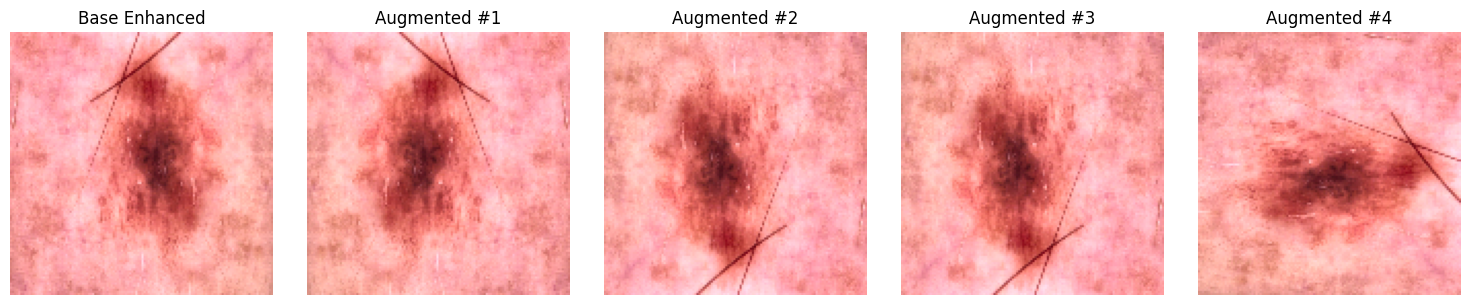

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(enhanced)
axes[0].set_title('Base Enhanced')
axes[0].axis('off')

for i in range(1, 5):
    aug = augment_image_array(enhanced)
    axes[i].imshow(aug)
    axes[i].set_title(f'Augmented #{i}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 3. Verify Zero Data Leakage Split

In [4]:
metadata_path = os.path.join('dataset', 'raw', 'HAM10000_metadata.csv')
df = pd.read_csv(metadata_path)
train_df, val_df, test_df = create_leak_free_splits(df)

train_lesions = set(train_df['lesion_id'])
val_lesions = set(val_df['lesion_id'])
test_lesions = set(test_df['lesion_id'])

print(f'Train: {len(train_df)} images ({len(train_lesions)} unique lesions)')
print(f'Val:   {len(val_df)} images ({len(val_lesions)} unique lesions)')
print(f'Test:  {len(test_df)} images ({len(test_lesions)} unique lesions)')
print('Train-Val Overlap:', len(train_lesions.intersection(val_lesions)))
print('Train-Test Overlap:', len(train_lesions.intersection(test_lesions)))
print('Val-Test Overlap:', len(val_lesions.intersection(test_lesions)))
print('Zero data leakage verified successfully!')

2026-10-28 17:31:40,530 - INFO - Split completed: Train=7054 images, Val=1464 images, Test=1497 images


Train: 7054 images (5228 unique lesions)
Val:   1464 images (1121 unique lesions)
Test:  1497 images (1121 unique lesions)
Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0
Zero data leakage verified successfully!


## 4. Verify Processed Storage

In [5]:
npz_path = os.path.join('dataset', 'processed', 'preprocessed_data.npz')
data = np.load(npz_path)
print('Preprocessed Data Keys:', list(data.keys()))
print('X_train:', data['X_train'].shape, 'dtype:', data['X_train'].dtype)
print('X_val:  ', data['X_val'].shape, 'dtype:', data['X_val'].dtype)
print('X_test: ', data['X_test'].shape, 'dtype:', data['X_test'].dtype)

Preprocessed Data Keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']


X_train: (7054, 128, 128, 3) dtype: float32


X_val:   (1464, 128, 128, 3) dtype: float32


X_test:  (1497, 128, 128, 3) dtype: float32
